# Constellation Software Inc. (TSX: CSU): Buffett-style investment memo
Date: October 2026. Price used: C$3,395, close on 23 Oct 2026. Company figures in USD millions. Share price in CAD.
This notebook is analysis for learning and portfolio use. It is not investment advice.
Method in brief: business model, competitive advantage, cash generation, capital allocation, risks, and valuation.
Sources are listed in the README and in the report. Secondary data sources differ in rounding, so figures are shown to the nearest million.

In [1]:
import pandas as pd, numpy as np
pd.set_option("display.width", 200)
df = pd.read_csv("data/csu_annual_2016_2025.csv")
df

,year,revenue_usd_m,operating_income_usd_m,net_income_attributable_usd_m,operating_cash_flow_usd_m,capex_usd_m,free_cash_flow_usd_m,depreciation_amortisation_usd_m,owner_earnings_proxy_usd_m,dividends_paid_usd_m,other_investing_outflow_usd_m,total_equity_attributable_usd_m,minority_interest_usd_m,interest_bearing_debt_usd_m,cash_and_short_term_investments_usd_m,invested_capital_usd_m
0,2016,2125,339,207,491,19,472,213,401,85,176,458,0,347,358,447
1,2017,2479,391,222,528,20,508,253,455,85,230,604,0,333,489,448
2,2018,3060,478,379,662,25,637,306,660,85,483,866,0,368,589,645
3,2019,3489,511,333,767,34,733,423,722,509,510,687,0,830,326,1191
4,2020,3969,682,436,1186,25,1161,508,919,85,487,1048,0,838,767,1119
5,2021,5106,870,310,1300,29,1271,639,920,85,1200,1061,460,1382,802,2101
6,2022,6622,920,512,1297,41,1256,819,1290,92,1700,1712,221,2317,926,3324
7,2023,8407,1182,565,1779,42,1737,1020,1543,85,1600,1876,85,3700,1314,4347
8,2024,10066,1471,731,2196,67,2129,1230,1894,85,1500,2795,493,4537,2014,5811
9,2025,11623,1928,512,2732,68,2664,1410,1854,85,1800,3575,692,5300,3152,6415


## 1. Ten years: revenue, profit, and cash
Net income attributable is the profit for common shareholders. Total net income in some years differs because of noncontrolling interests and revaluation items. That difference is a key point in this memo: reported profit alone does not show cash generation.

In [2]:
df["revenue_growth_pct"] = df["revenue_usd_m"].pct_change() * 100
df["operating_margin_pct"] = df["operating_income_usd_m"] / df["revenue_usd_m"] * 100
df["fcf_margin_pct"] = df["free_cash_flow_usd_m"] / df["revenue_usd_m"] * 100
df[["year", "revenue_usd_m", "revenue_growth_pct", "operating_income_usd_m", "operating_margin_pct",
    "net_income_attributable_usd_m", "operating_cash_flow_usd_m", "free_cash_flow_usd_m", "fcf_margin_pct"]].round(1)

,year,revenue_usd_m,revenue_growth_pct,operating_income_usd_m,operating_margin_pct,net_income_attributable_usd_m,operating_cash_flow_usd_m,free_cash_flow_usd_m,fcf_margin_pct
0,2016,2125,NaN,339,16.0,207,491,472,22.2
1,2017,2479,16.7,391,15.8,222,528,508,20.5
2,2018,3060,23.4,478,15.6,379,662,637,20.8
3,2019,3489,14.0,511,14.6,333,767,733,21.0
4,2020,3969,13.8,682,17.2,436,1186,1161,29.3
5,2021,5106,28.6,870,17.0,310,1300,1271,24.9
6,2022,6622,29.7,920,13.9,512,1297,1256,19.0
7,2023,8407,27.0,1182,14.1,565,1779,1737,20.7
8,2024,10066,19.7,1471,14.6,731,2196,2129,21.2
9,2025,11623,15.5,1928,16.6,512,2732,2664,22.9


In [3]:
print("Revenue CAGR 2016 to 2025:", round(((11623/2125) ** (1/9) - 1) * 100, 1), "%")
print("Free cash flow CAGR 2016 to 2025:", round(((2664/472) ** (1/9) - 1) * 100, 1), "%")
print("Recurring revenue share 2024: 7,396 / 10,066 =", round(7396/10066 * 100, 1), "%")
print("Recurring revenue share 2025: 8,700 / 11,623 =", round(8700/11623 * 100, 1), "%")

Revenue CAGR 2016 to 2025: 20.8 %
Free cash flow CAGR 2016 to 2025: 21.2 %
Recurring revenue share 2024: 7,396 / 10,066 = 73.5 %
Recurring revenue share 2025: 8,700 / 11,623 = 74.9 %


## 2. Owner earnings proxy and pre-tax return on invested capital
Owner earnings proxy = net income attributable + depreciation and amortisation - capital expenditure.
This proxy is an upper bound. Depreciation and amortisation includes amortisation of acquired intangibles, and that amortisation reflects part of the price paid for acquisitions. Free cash flow is shown beside it for comparison.
Invested capital = total equity attributable + minority interest + interest-bearing debt - cash and short-term investments.
Pre-tax return on invested capital = operating income / average invested capital. 2016 is not shown because 2015 invested capital was not verified on the same basis.

In [4]:
df["avg_invested_capital"] = df["invested_capital_usd_m"].rolling(2).mean()
df["roic_pre_tax_pct"] = df["operating_income_usd_m"] / df["avg_invested_capital"] * 100
df[["year", "net_income_attributable_usd_m", "depreciation_amortisation_usd_m", "capex_usd_m",
    "owner_earnings_proxy_usd_m", "free_cash_flow_usd_m", "invested_capital_usd_m", "roic_pre_tax_pct"]].round(1)

,year,net_income_attributable_usd_m,depreciation_amortisation_usd_m,capex_usd_m,owner_earnings_proxy_usd_m,free_cash_flow_usd_m,invested_capital_usd_m,roic_pre_tax_pct
0,2016,207,213,19,401,472,447,NaN
1,2017,222,253,20,455,508,448,87.4
2,2018,379,306,25,660,637,645,87.5
3,2019,333,423,34,722,733,1191,55.7
4,2020,436,508,25,919,1161,1119,59.0
5,2021,310,639,29,920,1271,2101,54.0
6,2022,512,819,41,1290,1256,3324,33.9
7,2023,565,1020,42,1543,1737,4347,30.8
8,2024,731,1230,67,1894,2129,5811,29.0
9,2025,512,1410,68,1854,2664,6415,31.5


## 3. Capital allocation
Free cash flow is the cash after operating cash flow less capital expenditure. Other investing outflow is used as a proxy for acquisition spending. It is not a verified acquisition-only line, and the report states that limit. Dividends paid stayed near US$85 million in most years, except 2019, when the reported figure was US$509 million.

In [5]:
df[["year", "free_cash_flow_usd_m", "other_investing_outflow_usd_m", "dividends_paid_usd_m"]].round(0)
print("Total free cash flow 2016 to 2025 (USD millions):", int(df["free_cash_flow_usd_m"].sum()))
print("Total other investing outflow 2016 to 2025 (USD millions):", int(df["other_investing_outflow_usd_m"].sum()))
print("Total dividends paid 2016 to 2025 (USD millions):", int(df["dividends_paid_usd_m"].sum()))

Total free cash flow 2016 to 2025 (USD millions): 12568
Total other investing outflow 2016 to 2025 (USD millions): 9686
Total dividends paid 2016 to 2025 (USD millions): 1281


## 4. Valuation check: price against free cash flow
Market value at the price used: 21.19 million shares x C$3,395 = C$71,940 million. At 1.40 CAD per USD, that is US$51,386 million. Divided by 2025 free cash flow of US$2,664 million, the multiple is 19.3 times. The full DCF, with cases and sensitivities, is in the Excel model.

In [6]:
shares = 21.19
price_cad = 3395
fx = 1.40
market_value_cad = shares * price_cad
market_value_usd = market_value_cad / fx
print("Market value (CAD millions):", round(market_value_cad, 0))
print("Market value (USD millions):", round(market_value_usd, 0))
print("Price / 2025 free cash flow:", round(market_value_usd / 2664, 1))
print("Price in USD:", round(price_cad / fx, 0))
print("2025 earnings per share, attributable (USD): 24.15, from StockAnalysis")
print("Price in USD / 2025 earnings per share:", round((price_cad / fx) / 24.15, 1))

Market value (CAD millions): 71940.0
Market value (USD millions): 51386.0
Price / 2025 free cash flow: 19.3
Price in USD: 2425.0
2025 earnings per share, attributable (USD): 24.15, from StockAnalysis
Price in USD / 2025 earnings per share: 100.4


## 5. Charts
Charts are built by scripts/build_charts.py and saved in charts/.

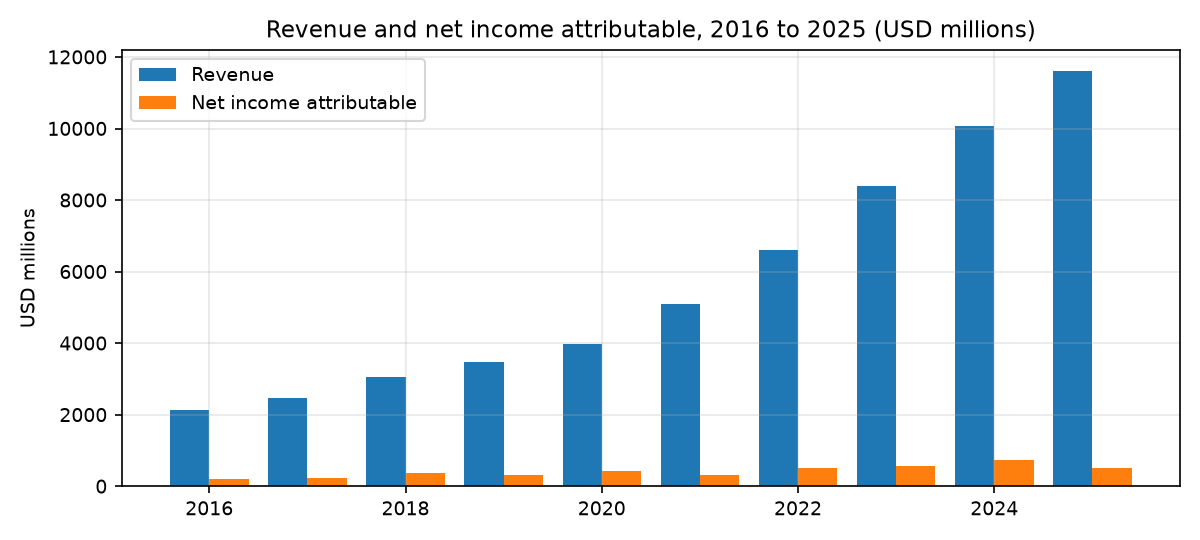

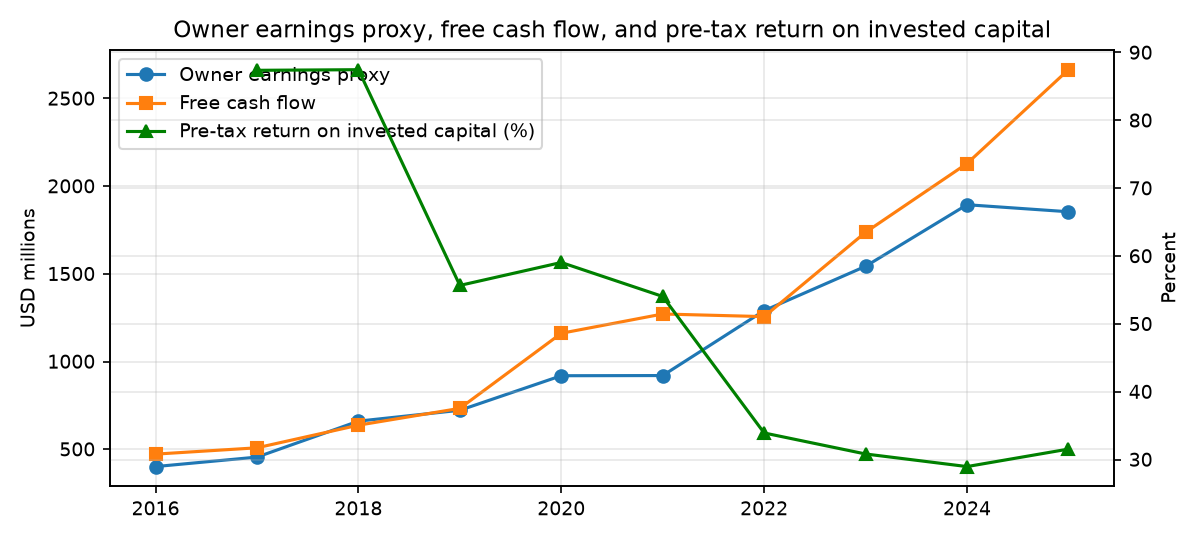

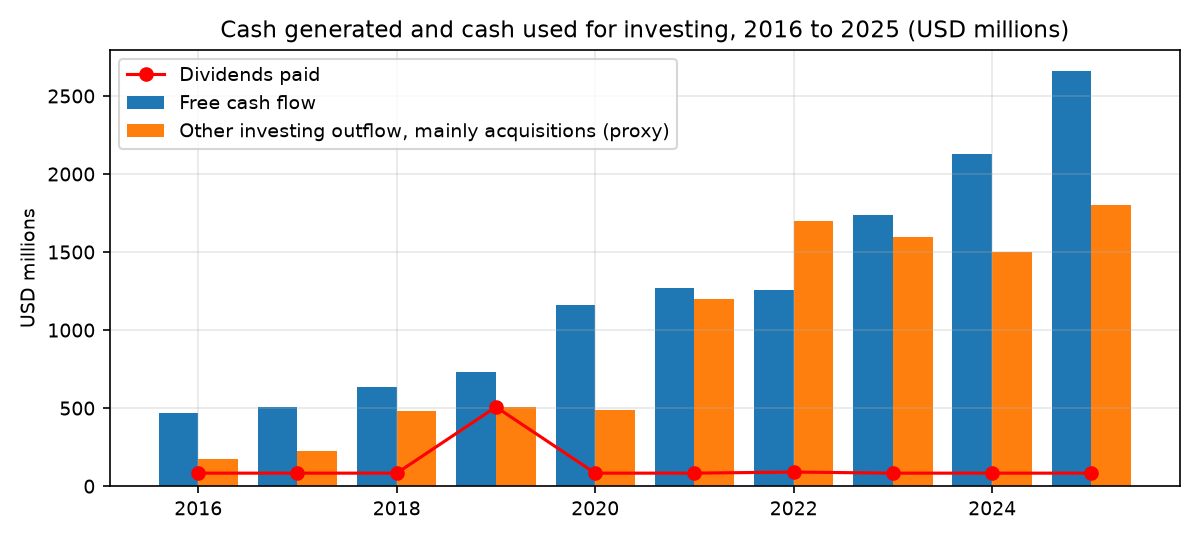

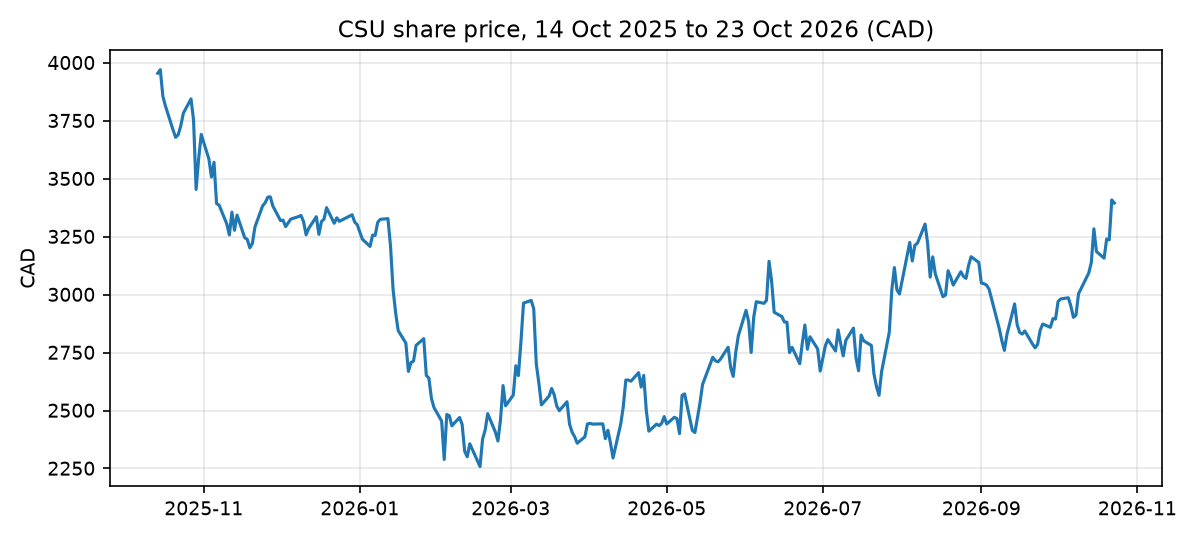

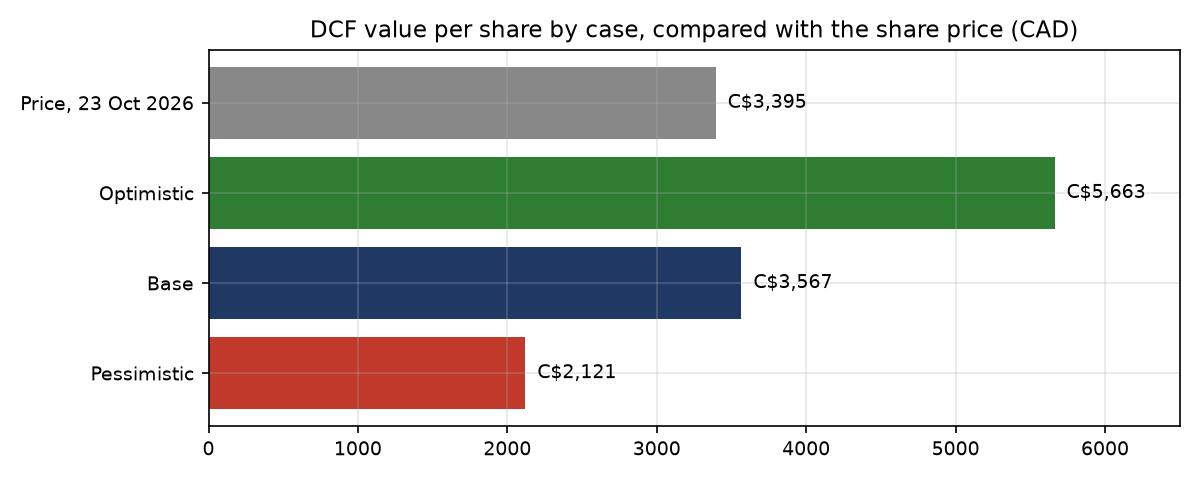

In [7]:
from IPython.display import Image, display
for name in ["revenue_vs_income.png", "roic_and_owner_earnings.png", "capital_allocation.png", "price_history.png", "football_field.png"]:
    display(Image(filename=f"charts/{name}"))